## 1.1 Windowing synthetic data

Creating the energy matrix

In [1]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import blackmanharris

In [2]:
np.random.seed(2)
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 1000
gaussian_noise_std = amp_sin_waves * 0.1 # set the standard devaition of the noise
test_frequencies = [2e6,2e6]
i = 0

plotting windows


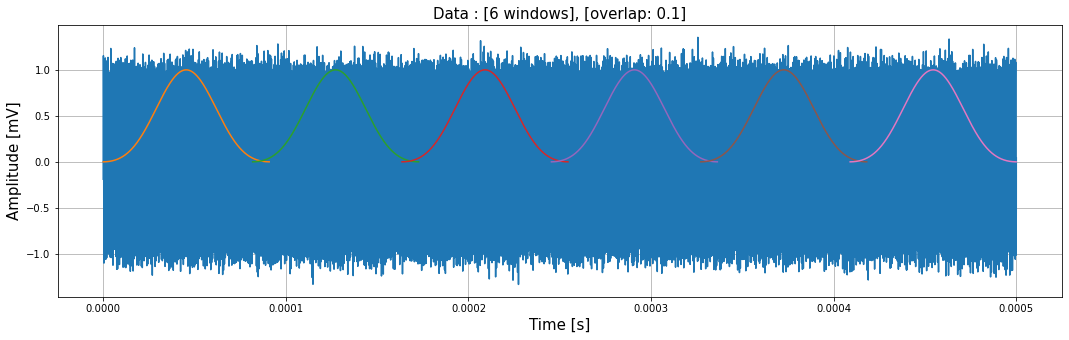

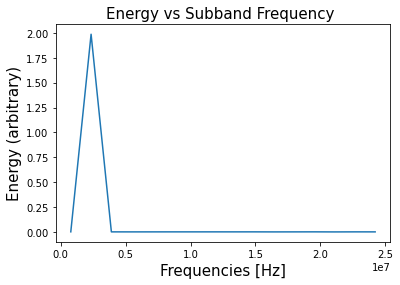

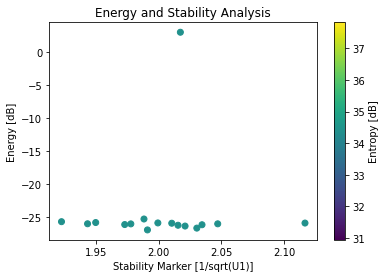

transform energy 3271.7262713533714
signal energy 12757.448909585259
plotting windows


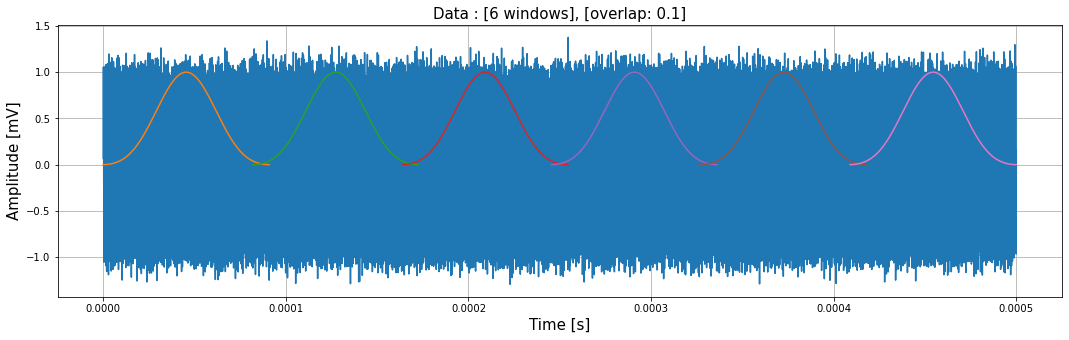

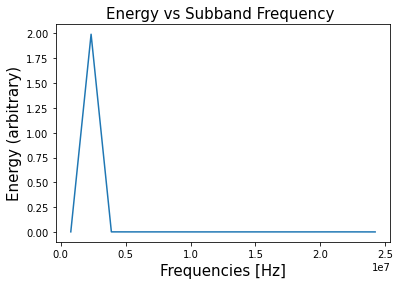

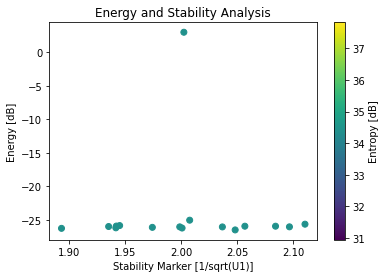

transform energy 3279.5428150471644
signal energy 12771.50532082544


In [4]:
for frequency in test_frequencies:
    if i == 0:
        harmonics = np.array([1/3,1/2,1,2,3])
        frequencies = frequency*harmonics # create list of frequencies for synthetic data
        i += 1
    else:
        frequencies = [frequency]
    time_period = 1/frequency
    signal_duration = no_time_periods*time_period
    delay = None
    end = None

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, 0, signal_duration, 
        sampling_rate, delay, end
        )
    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std, signal_duration, sampling_rate)
    data += gaussian_noise

    # transform parameters
    levels = 4
    db_order = 30
    wavelet = f'db{db_order}'
    mode = 'symmetric'

    # create SVD object which windows, transforms, and performs SVD
    windows = 6
    overlap = 0.1
    SVD_object = SVD(data, windows, levels, overlap, wavelet, sampling_rate)

    # important parameters
    win_data_shape = SVD_object.windowed_data.shape

    # create plots to show windowed data
    win_len = SVD_object.windowed_data.shape[1]
    fig1,ax1 = plt.subplots()
    fig1.set_size_inches(18,5)
    plot.plot_wave(data,t_plot,ax1,f': [{windows} windows], [overlap: {round(SVD_object.overlap,2)}]')
    blackman_window = np.blackman(win_len)
    zeros = np.zeros(data.shape)
    offset = 0

    plot_windows = True
    if plot_windows:
        print('plotting windows')
        for _ in range(windows): # plot windows
            time_plot = t_plot[offset:offset+win_len]
            ax1.plot(time_plot,blackman_window)
            offset += SVD_object.offset
    plt.show()
    # wpt
    transform_object = wpt.dwpt(data*blackmanharris(len(data)),levels,wavelet,mode)

    # plot frequencies
    plot.plot_energy_vs_freq(transform_object,sampling_rate)

    # some useful functions
    def compute_shannon_entropy(data):
        '''
        Calculates the shannon entropy of an array.
        Same implementation as the matlab function wentropy.
        '''
        return -np.sum(data**2*np.log(data**2)) 
    
    # plot energy, entropy, and stability
    stability_markers = SVD_object.stability_marker

    energy = list(transform_object.info()["energy"])
    log_energy = 10*np.log10(energy)

    entropy = []
    for node in transform_object.get_level(): # final level nodes
        reconstructed_wave = inv.inv_dwpt(transform_object, nodes=node.path)
        entropy.append(compute_shannon_entropy(reconstructed_wave))
    
    entropy = 10*np.log10(entropy)
    fig2,ax2 = plt.subplots()
    im = ax2.scatter(stability_markers,log_energy,c=entropy)
    ax2.set_xlabel('Stability Marker [1/sqrt(U1)]')
    ax2.set_ylabel('Energy [dB]')
    ax2.set_title('Energy and Stability Analysis')
    fig2.colorbar(im,ax=ax2,label='Entropy [dB]')
    plt.show()

    # comparing energy of data and energy of the transformed data
    print('transform energy',transform_object.calc_total_energy())
    print('signal energy',np.sum(data**2))
    # print('norm energy matrix',SVD_object.norm_energy_matrix)

## Appendix

Testing SVD behaviour

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# generate noisy linear relationship
gradient_y = 4
gradient_z = 7
offset = 1000 # y-intercept
gauss_variance = 0.01

x = np.arange(0,10,0.01)
y = gradient_y*x# codes for y with and without correrlation with x
y = np.random.rand(x.shape[0])+7
# y*=50
y += np.random.normal(offset,gauss_variance,x.shape)
z = gradient_z*x
z += np.random.normal(offset,gauss_variance,x.shape)
plt.scatter(x,y)
plt.show()
u = np.c_[x,y] # concatenate into one matrix
# svd without centering
svd = np.linalg.svd(u)
eig = svd[2][0]
print('non-centred eigenvector',eig)
eig*=1/eig[0]
print('non-centered eigenvector',eig)

# centre 
means = (x.mean(),y.mean())
print('means',means)
m = np.zeros(u.shape)
for i in range(u.shape[0]):
    for j in range(u.shape[1]):
        m[i,j]=u[i,j]-means[j]
plt.scatter(m[:,0],m[:,1])
plt.show()

# svd with centering
svd = np.linalg.svd(m)
eig = svd[2][0]
print('centred eigenvector',eig)
eig*=1/eig[0]
print('centered eigenvector',eig)

# divide by mean
n = np.zeros(u.shape)
for i in range(u.shape[0]):
    for j in range(u.shape[1]):
        n[i,j]=u[i,j]/means[j]
plt.scatter(n[:,0],n[:,1])
plt.show()

# svd with centering
svd = np.linalg.svd(n)
eig = svd[2][0]
print('divide by mean eigenvector',eig)
eig*=1/eig[0]
print('divide by mean eigenvector',eig)

slope, i,r,p,st_error = stats.linregress(x,y)
print('slope from linear regression',slope)

### Testing SVD with synthetic energy matrix

In [ ]:
import numpy as np
from scipy import stats

# input array
input1 = np.array([[10,  5,     0,  10],
                   [10,  5,     50, 0],
                   [10,  5,     0,  0],
                   [10.1,5.05,  0,  0]])
input2 = np.array([[10,  5,     1,  10],
                   [10,  5,     50, 1],
                   [10,  5,     1,  1],
                   [10.1,5.05,  1,  1]])
input3 = np.array([[10,  5,     0,  10],
                   [10,  5,     50, 0],
                   [10,  5,     0,  0],
                   [10.1,5.1,   0,  0]])
input4 = np.array([[10,  5,     0.1,  1],
                   [10,  5,     1,    0.1],
                   [10,  5,     0.1,  0.1],
                   [10.1,5.5,   0.1,  0.1]])
x = input4
x_svd = np.linalg.svd(x)[2][0] # svd of original array

print('input array\n',x)
print('\nno normalisation\n',x_svd/x_svd[0])

# normalise by dividing with mean
x_norm = np.zeros(x.shape)
for column in range(x.shape[1]):
    mean = np.mean(x[:,column])
    x_norm[:,column] = x[:,column]/mean

# centre with mean
x_centre = np.zeros(x.shape)
for column in range(x.shape[1]):
    mean = np.mean(x[:,column])
    x_centre[:,column] = x[:,column]-mean

# normalise by dividing with kernel peak
x_kernel = np.zeros(x.shape)
for column in range(x.shape[1]):
    data = x[:,column]
    kde = stats.gaussian_kde(data) # equivalent of ksdensity in matlab
    u = np.linspace(data.min(), data.max(), 100)
    p = kde(u) # probability density estmate evaluated at 100 points (given by x)
    kernel_peak = u[p.argmax()]
    x_kernel[:,column] = x[:,column]/kernel_peak

# svd of each normalisation method
x_norm_svd = np.linalg.svd(x_norm)[2][0]
x_centre_svd = np.linalg.svd(x_centre)[2][0]
x_kernel_svd = np.linalg.svd(x_kernel)[2][0]

# display results
print('\ncentre with mean\n',x_centre_svd/x_centre_svd[0])
print('\ndivide by mean\n',x_norm_svd/x_norm_svd[0])
print('\ndivide by kernel peak\n',x_kernel_svd/x_kernel_svd[0])

Testing relationship between energy: $$\frac{1}{n}X^{T}X$$ and variance.

In [ ]:
variances = []
energy = []
data = []
for x in range(200):
    d = 2*(np.random.rand(200)-0.5)
    data.append(d)
    variances.append(np.var(d))
    energy.append(1/len(d)*np.linalg.norm(d)**2)
table = np.c_[variances,energy]
plt.scatter(variances,energy)
plt.xlabel('variance')
plt.ylabel('energy')

# svd with centering
svd = np.linalg.svd(table)
eig = svd[2][0]
eig*=1/eig[0]
print('centered eigenvalue',eig)

Testing implementation of stability markers

In [ ]:
eigenvector = np.array([-1,2,3])
print(np.abs(eigenvector))
stability_markers = []
for i in eigenvector:
    stability_markers.append(np.sqrt(1/abs(i)))
print(stability_markers)
print(np.sqrt(1/abs(eigenvector)))

Testing implementation of ksdensity equivalent

In [ ]:
from scipy import stats
data = np.array([1,2,3,4,5,6,301,302,303,304,305,306])
kde = stats.gaussian_kde(data)
x = np.linspace(data.min(), data.max(), 10000000)
p = kde(x)
kernel_peak = x[p.argmax()]
print('kernel peak',kernel_peak)
print('average',np.average(data))

### Testing energy vs entropy

In [ ]:
np.random.seed(40)
energies = []
entropy = []
for _ in range(10000):
    wave = np.random.rand(10)
    energies.append(1/len(wave)*sum(wave**2))
    entropy.append(compute_shannon_entropy(wave))
    if entropy[-1]<1:
        plt.plot(wave)
        plt.title('low entropy')
        plt.show()
        print(np.average(wave))
    if entropy[-1]>3.5:
        plt.plot(wave)
        plt.title('high entropy')
        plt.show()
        print(np.average(wave))
plt.scatter(entropy,energies)
plt.xlabel('entropy')
plt.ylabel('energy')
plt.show()

### Testing windowing

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
def multi_window(data,windows,input_overlap):
    '''
    create overlapping blackman windows on the data

    Parameters
    ----------
    data: array
        the data to be windowed
    windows: int
        the number of windows
    
    Returns
    -------
    windowed_data: array
        a matrix of the windowed data, 1 window per row
    actual_overlap: float
        the actual overlap is greater than specified
    '''
    # input parameters
    data = data
    windows = windows

    # create window
    window_size,offset = calc_win_size(data,windows,input_overlap)
    window = 1 #np.blackman(window_size)

    # calculate actual overlap
    actual_overlap = 1-offset/window_size

    # window the data and store in a matrix
    start = 0
    end = start + window_size
    windowed_data = np.zeros((windows,window_size))
    for i in range(windows):
        data_segment = data[start:end] # segment data according to window size
        windowed_data[i,:] = data_segment#*window # store each window in a row
        start += offset
        end = start + window_size

    return windowed_data,actual_overlap,offset

def calc_win_size(data,windows,input_overlap):
    '''
    calculates the window length for the specified parameters. Always rounds down, 
    giving a  greater window overlap than specified. this can be mitigated by using 
    larger windows by increasing the length of the data or reducing the number of 
    windows. This algorithm optimises for using more data instead of obtaining an 
    accurate overlap.

    Parameters
    ----------
    self: SVD object

    Returns
    -------
    win_size: int
        the length of the window array
    offest: int
        the distance between neighbouring windows
    '''
    # input parameters
    data_len = len(data)
    windows = windows
    overlap = input_overlap

    # calculate window size
    win_size = int(data_len/((windows-1)*(1-overlap)+1)) # calculate window size, round down
    offset = int((1-overlap)*win_size) # calculate and round offset
    return win_size,offset

data = [i for i in range(50)]
windows = 2
x,y,z = multi_window(data,windows,0.1)
for i in range(x.shape[0]):
    print(x[i,:])